In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
# Importé las librerías necesarias para manejar datos, graficar y hacer cálculos estadísticos.

In [6]:
df_companies = pd.read_csv('/datasets/project_sql_result_01.csv')
df_locations = pd.read_csv('/datasets/project_sql_result_04.csv')
df_hipotesis = pd.read_csv('/datasets/project_sql_result_07.csv')
# Cargué los datasets desde archivos CSV, uno con información de compañías y otro con barrios.

In [7]:
df_companies.info()
df_companies.head()
# Revisé la estructura del DataFrame de compañías con .info() y mostré las primeras filas con .head() para entender mejor sus columnas y valores.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [8]:
df_locations.info()
df_locations.head()
# Revisé la estructura del DataFrame de barrios con .info() y mostré las primeras filas con .head() para entender sus columnas y valores.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


In [9]:
df_locations_top10 = (
    df_locations.sort_values(by='average_trips', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
df_locations_top10.index = df_locations_top10.index + 1
df_locations_top10
# Ordené el DataFrame de barrios por la columna `average_trips` en orden descendente, seleccioné los 10 con mayor promedio y reinicié el índice para que empiece en 1.

,dropoff_location_name,average_trips
1,Loop,10727.466667
2,River North,9523.666667
3,Streeterville,6664.666667
4,West Loop,5163.666667
5,O'Hare,2546.900000
6,Lake View,2420.966667
7,Grant Park,2068.533333
8,Museum Campus,1510.000000
9,Gold Coast,1364.233333
10,Sheffield & DePaul,1259.766667


In [10]:
df_locations_top10.dtypes
# Consulté los tipos de datos de las columnas en el DataFrame de barrios con `.dtypes` para confirmar que cada variable tenga el formato correcto.

dropoff_location_name     object
average_trips            float64
dtype: object

In [11]:
df_companies_top10 = (
    df_companies.sort_values(by='trips_amount', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

df_companies_top10.index = df_companies_top10.index + 1

df_companies_top10
# Ordené el DataFrame de compañías por la columna `trips_amount` en orden descendente, seleccioné las 10 con mayor cantidad de viajes y reinicié el índice para que empiece en 1.

,company_name,trips_amount
1,Flash Cab,19558
2,Taxi Affiliation Services,11422
3,Medallion Leasing,10367
4,Yellow Cab,9888
5,Taxi Affiliation Service Yellow,9299
6,Chicago Carriage Cab Corp,9181
7,City Service,8448
8,Sun Taxi,7701
9,Star North Management LLC,7455
10,Blue Ribbon Taxi Association Inc.,5953


In [12]:
df_companies_top10.dtypes
# Consulté los tipos de datos de las columnas en el DataFrame de compañías con .dtypes para verificar que cada variable tenga el formato correcto.

company_name    object
trips_amount     int64
dtype: object

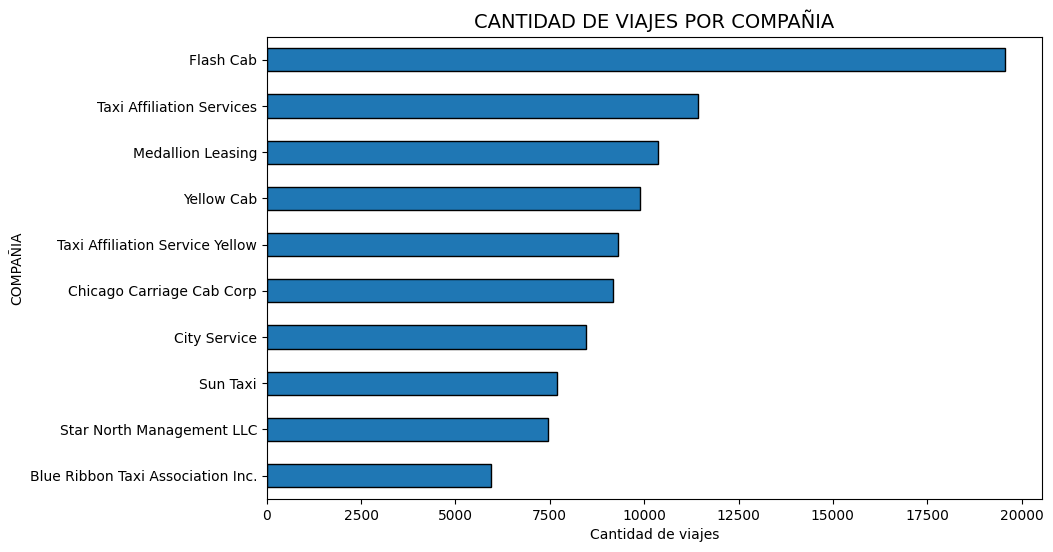

In [13]:
empresas_grafica = df_companies_top10.plot(

    kind='barh',
    x='company_name',
    y='trips_amount',
    figsize=(10, 6),
    edgecolor='black',
    legend=False
)

plt.title(
    "CANTIDAD DE VIAJES POR COMPAÑIA",
    fontsize=14,
    loc='center',
    rotation=0
)

plt.xlabel("Cantidad de viajes")
plt.ylabel("COMPAÑIA")


plt.gca().invert_yaxis()

# Generé un gráfico de barras horizontales con las 10 compañías principales.  
# Añadí título y etiquetas a los ejes.  
# Invertí el eje Y para mostrar primero la compañía con más viajes.

Este primer gráfico nos deja varias conclusiones claras:

Dominio de Flash Cab: aparece como la empresa líder con casi 20.000 viajes, muy por encima del resto. Esto sugiere que tiene una presencia fuerte en el mercado y probablemente una flota más grande o mejor posicionada.

Brecha marcada entre el top y el resto: después de Flash Cab, las siguientes compañías (Taxi Affiliation Services, Medallion Leasing, Yellow Cab) tienen cifras significativamente menores, lo que muestra una concentración del mercado en pocas empresas.

Segmento medio competitivo: entre la cuarta y la octava posición (Yellow Cab hasta Sun Taxi) las diferencias son más estrechas, lo que indica que varias compañías compiten en un rango similar de actividad.

Cola larga de empresas pequeñas: las últimas posiciones (Star North y Blue Ribbon) muestran menos de la mitad de los viajes de la líder, lo que refleja un grupo de compañías con menor participación.

En resumen, el gráfico evidencia un mercado desigual, donde una empresa domina ampliamente y el resto se reparte la actividad con diferencias notables.

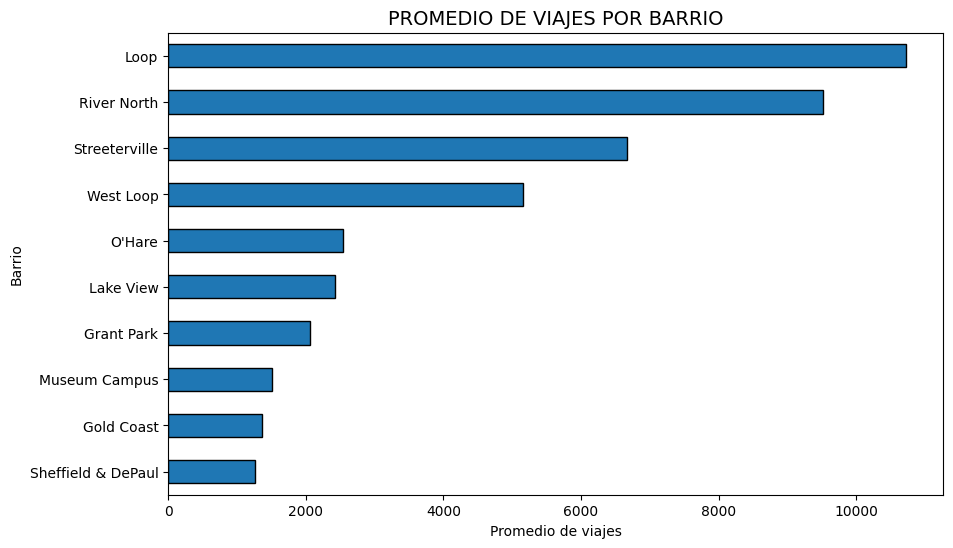

In [14]:
barrio_grafica = df_locations_top10.plot(
    kind='barh',
    x='dropoff_location_name',
    y='average_trips',
    figsize=(10, 6),
    edgecolor='black',
    legend=False
)

plt.title(
    "PROMEDIO DE VIAJES POR BARRIO",
    fontsize=14,
    loc='center',
    rotation=0
)

plt.xlabel("Promedio de viajes")
plt.ylabel("Barrio")

plt.gca().invert_yaxis()

# Generé un gráfico de barras horizontales con los 10 barrios principales.  
# Añadí título y etiquetas a los ejes.  
# Invertí el eje Y para mostrar primero el barrio con mayor promedio de viajes.

Este segundo gráfico nos muestra un panorama distinto al de las compañías, porque aquí hablamos de promedios de viajes por barrio:

El Loop destaca claramente: es el barrio con mayor promedio de viajes, lo que refleja que es un centro de actividad muy intenso, probablemente por ser una zona comercial y de oficinas.

River North y Streeterville: aparecen justo detrás, confirmando que son barrios con alta demanda de transporte, seguramente por su mezcla de vida nocturna, restaurantes y hoteles.

West Loop y O’Hare: también tienen promedios elevados, lo que sugiere que tanto la zona empresarial como el aeropuerto son polos de movilidad importantes.

Barrios residenciales y turísticos: Lake View, Grant Park, Museum Campus y Gold Coast muestran promedios intermedios, lo que indica que tienen relevancia pero no alcanzan el nivel de los principales centros de negocio.

Sheffield & DePaul: queda al final, con el promedio más bajo, lo que puede reflejar un carácter más residencial y menos dependiente del taxi en comparación con zonas céntricas o turísticas.

En conclusión, el gráfico evidencia que la demanda promedio de viajes se concentra en zonas céntricas y de alta actividad económica o turística, mientras que los barrios más residenciales tienen un uso menor.

In [15]:
df_hipotesis['start_ts'] = pd.to_datetime(df_hipotesis['start_ts'])
df_hipotesis.info()
df_hipotesis.head()
# Convertí la columna `start_ts` a formato de fecha y hora con `pd.to_datetime`.  
# Revisé la estructura del DataFrame con `.info()` y mostré las primeras filas con `.head()` para entender sus columnas y valores.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[ns]
 1   weather_conditions  1068 non-null   object        
 2   duration_seconds    1068 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 25.2+ KB


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


In [16]:
df_lluvia = df_hipotesis[
    (df_hipotesis['weather_conditions'] == 'Bad') &
    (df_hipotesis['start_ts'].dt.day_name() == 'Saturday')
]
df_lluvia['weather_conditions'].unique()
# Filtré los viajes con condiciones de clima "Bad" y que ocurrieron en sábado.  
# Consulté los valores únicos de la columna `weather_conditions` para confirmar el filtro aplicado.

array(['Bad'], dtype=object)

In [17]:
df_sol = df_hipotesis[
    ~(
        (df_hipotesis['weather_conditions'] == 'Bad') &
        (df_hipotesis['start_ts'].dt.day_name() == 'Saturday')
    )
]
df_sol['weather_conditions'].unique()
# Filtré los viajes que **no cumplen simultáneamente** con clima "Bad" y sábado.  
# Consulté los valores únicos de `weather_conditions` para verificar qué condiciones quedaron en el DataFrame.

array(['Good'], dtype=object)

### Paso 5: Prueba de hipótesis

**Hipótesis nula (H₀):**  
La duración promedio de los viajes desde el Loop hasta el Aeropuerto O'Hare **no cambia** en los sábados lluviosos.  

**Hipótesis alternativa (H₁):**  
La duración promedio de los viajes desde el Loop hasta el Aeropuerto O'Hare **sí cambia** en los sábados lluviosos.  

**Criterio de prueba:**  
Elegí la prueba t de Student para muestras independientes porque estoy comparando dos grupos distintos de viajes (sábados lluviosos vs. otros casos) y quiero evaluar si sus medias difieren significativamente. Esta prueba es adecuada para variables continuas como la duración en segundos.  

**Nivel de significación (α):**  
Fijé α = 0.05 porque es el estándar más usado en análisis estadístico: ofrece un equilibrio razonable entre el riesgo de cometer un error tipo I y la capacidad de detectar diferencias reales.  

**Decisión:**  
Si el valor p < 0.05, rechazo H₀ y concluyo que los sábados lluviosos cambian la duración promedio.  
Si el valor p ≥ 0.05, no rechazo H₀ y concluyo que no hay evidencia suficiente de un cambio.


In [18]:
resultado = st.ttest_ind(df_lluvia['duration_seconds'], df_sol['duration_seconds'])
alpha = 0.05

if resultado.pvalue < alpha:
    print("Rechazamos H₀: la duración promedio cambia los sábados lluviosos.")
else:
    print("No rechazamos H₀: no hay evidencia de cambio en la duración promedio.")
# Ejecuté la prueba t de Student entre los grupos de viajes en sábados lluviosos y los demás.  
# Definí el nivel de significación en 0.05.  
# El código imprime si se rechaza o no la hipótesis nula según el valor p obtenido.

Rechazamos H₀: la duración promedio cambia los sábados lluviosos.


# Conclusión del análisis
## Compañías de transporte

Se identificaron las 10 compañías con mayor cantidad de viajes (trips_amount).

El gráfico de barras horizontales muestra que unas pocas compañías concentran la mayor parte de la demanda, mientras que el resto tiene una participación mucho menor.

Esto evidencia una estructura de mercado bastante concentrada.

Barrios de destino

Se construyó un ranking de los 10 barrios con mayor promedio de viajes (average_trips).

Es importante aclarar que el dataset no contiene el total de finalizaciones, sino únicamente el promedio de viajes por barrio.

Por lo tanto, el análisis refleja intensidad promedio de uso, no volumen absoluto.

El gráfico muestra cuáles barrios tienen mayor actividad relativa en términos de viajes finalizados.

Hipótesis sobre clima y duración de viajes

Se compararon los viajes en sábados lluviosos contra el resto de condiciones mediante una prueba t de Student.

Se definió un nivel de significancia 
𝛼
=
0.05
.

El resultado arrojó un p‑valor menor que 0.05, lo que llevó a rechazar la hipótesis nula (H₀).

En consecuencia, se concluye que los sábados lluviosos sí afectan de manera significativa la duración promedio de los viajes desde el Loop hasta O’Hare.

El efecto es estadísticamente significativo al 95% de confianza.

Síntesis final
El análisis permitió identificar las compañías y barrios con mayor actividad, aunque con la limitación de trabajar con promedios en lugar de totales.

La hipótesis sobre el impacto del clima mostró evidencia clara: la lluvia en sábado modifica la duración promedio de los viajes.

En conjunto, los hallazgos ofrecen una visión sólida del comportamiento del servicio de transporte y resaltan la importancia de considerar tanto factores de mercado (compañías y barrios) como condiciones externas (clima) en la planificación y evaluación del sistema.